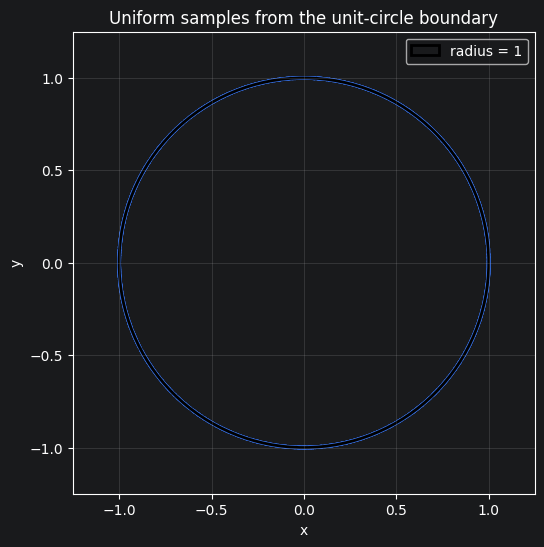

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Uniform sampling from the unit-circle boundary, S^1.
rng = np.random.default_rng(42)
n_points = 5_000
radius = 1.0
plot_limit = 1.25

theta = rng.uniform(0.0, 2.0 * np.pi, n_points)
points = radius * np.column_stack((np.cos(theta), np.sin(theta)))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.6, edgecolors="none")
ax.add_patch(plt.Circle(
    (0, 0), radius, fill=False, color="black", linewidth=2, label="radius = 1"
))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Uniform samples from the unit-circle boundary")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

Left Gaussian radial range: 0.9999999999999999 1.0
Right Gaussian radial range: 0.9999999999999999 1.0


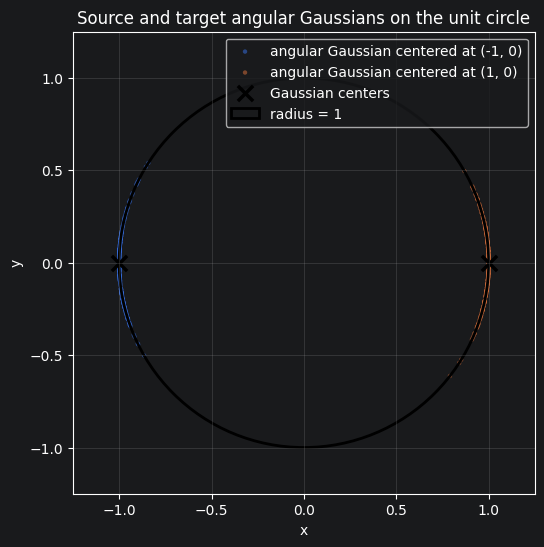

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Source and target clouds are angular Gaussians centered at the left and right
# points of the unit circle, then mapped onto S^1.
rng = np.random.default_rng(123)
radius = 1.0
plot_limit = 1.25
angular_variance = 0.04
angular_std = np.sqrt(angular_variance)
n_points_per_gaussian = 250

mean_left = np.array([-radius, 0.0])
mean_right = np.array([radius, 0.0])
angle_left = np.pi
angle_right = 0.0


def angles_to_circle(theta, radius=1.0):
    return radius * np.column_stack((np.cos(theta), np.sin(theta)))


def sample_angular_gaussian_on_circle(mean_angle, angular_std, n_samples, rng, radius=1.0):
    theta = rng.normal(loc=mean_angle, scale=angular_std, size=n_samples)
    return angles_to_circle(theta, radius=radius), theta


left_gaussian_points, left_gaussian_angles = sample_angular_gaussian_on_circle(
    angle_left, angular_std, n_points_per_gaussian, rng, radius
)
right_gaussian_points, right_gaussian_angles = sample_angular_gaussian_on_circle(
    angle_right, angular_std, n_points_per_gaussian, rng, radius
)

gaussian_circle_points = np.vstack((left_gaussian_points, right_gaussian_points))
gaussian_circle_labels = np.concatenate(
    (
        np.zeros(n_points_per_gaussian, dtype=int),
        np.ones(n_points_per_gaussian, dtype=int),
    )
)

print("Left Gaussian radial range:", np.linalg.norm(left_gaussian_points, axis=1).min(), np.linalg.norm(left_gaussian_points, axis=1).max())
print("Right Gaussian radial range:", np.linalg.norm(right_gaussian_points, axis=1).min(), np.linalg.norm(right_gaussian_points, axis=1).max())

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    left_gaussian_points[:, 0],
    left_gaussian_points[:, 1],
    s=10,
    alpha=0.55,
    edgecolors="none",
    label="angular Gaussian centered at (-1, 0)",
)
ax.scatter(
    right_gaussian_points[:, 0],
    right_gaussian_points[:, 1],
    s=10,
    alpha=0.55,
    edgecolors="none",
    label="angular Gaussian centered at (1, 0)",
)
ax.scatter(
    [mean_left[0], mean_right[0]],
    [mean_left[1], mean_right[1]],
    marker="x",
    s=120,
    linewidths=2.5,
    color="black",
    label="Gaussian centers",
)

circle_boundary = plt.Circle(
    (0, 0), radius, fill=False, color="black", linewidth=2, label="radius = 1"
)
ax.add_patch(circle_boundary)

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Source and target angular Gaussians on the unit circle")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

## Construction data for the kernel-profile comparison

The uniform unit-circle samples define the shared construction set for all five kernels. The angular Gaussian clouds provide starting points and visual context. Each profile is fitted on the same symmetric CkNN support, then supplies a Laplacian, biharmonic spectral embedding, continuous Nyström extension, and RFM vector field. The experiment compares raw and circle-guarded trajectories and checks their behavior when the Euler step size is halved.

all_generated_points shape: (5500, 2)
construction_points shape: (5000, 2)
construction source: uniform circle samples only
source counts:
  uniform circle: 5000
  left Gaussian: 250
  right Gaussian: 250


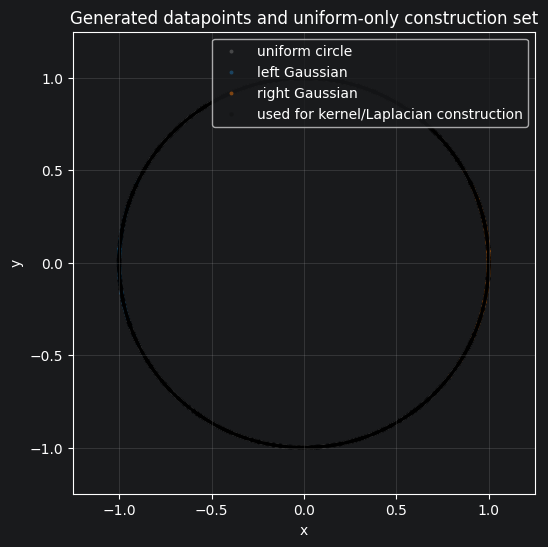

In [3]:
all_generated_points = np.vstack((points, gaussian_circle_points))
construction_points = points.astype(np.float32)

source_labels = np.concatenate(
    (
        np.full(points.shape[0], "uniform circle", dtype=object),
        np.where(gaussian_circle_labels == 0, "left Gaussian", "right Gaussian").astype(object),
    )
)

source_palette = {
    "uniform circle": "tab:gray",
    "left Gaussian": "tab:blue",
    "right Gaussian": "tab:orange",
}

print("all_generated_points shape:", all_generated_points.shape)
print("construction_points shape:", construction_points.shape)
print("construction source: uniform circle samples only")
print("source counts:")
for label in source_palette:
    print(f"  {label}: {np.sum(source_labels == label)}")

fig, ax = plt.subplots(figsize=(7, 6))
for label, color in source_palette.items():
    mask = source_labels == label
    ax.scatter(
        all_generated_points[mask, 0],
        all_generated_points[mask, 1],
        s=8,
        alpha=0.45,
        edgecolors="none",
        color=color,
        label=label,
    )

ax.scatter(
    construction_points[:, 0],
    construction_points[:, 1],
    s=10,
    alpha=0.18,
    edgecolors="none",
    color="black",
    label="used for kernel/Laplacian construction",
)
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black", linewidth=2))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-plot_limit, plot_limit)
ax.set_ylim(-plot_limit, plot_limit)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Generated datapoints and uniform-only construction set")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.show()

### Shared circle projection and tangent helpers

Every profile uses the same unit-circle geometry and probes. Point projection normalizes each nonzero point to radius one. The circle is one-dimensional in its two-dimensional ambient space, so its tangent-space guard removes the radial component of velocity, $v-(v\cdot n)n$, where $n=x/\|x\|$. The circle has no boundary. The raw trajectories evaluate the analytical field directly; the guarded trajectories use this common tangent projection and project after every Euler step.

In [4]:
import jax.numpy as jnp
from cellflow.ode_solver._rfm_interpolation import RFMInterpolation


def in_circle(samples, radius=radius, tol=1e-4):
    radii = np.linalg.norm(samples, axis=-1)
    return np.abs(radii - radius) <= tol


def project_to_circle(x, radius=radius, eps=1e-12):
    x = jnp.asarray(x)
    point_radius = jnp.linalg.norm(x, axis=-1, keepdims=True)
    fallback_direction = jnp.zeros_like(x).at[..., 0].set(1.0)
    direction = jnp.where(
        point_radius > eps, x / jnp.maximum(point_radius, eps), fallback_direction
    )
    return radius * direction


def project_circle_velocity_to_tangent(x, v):
    v = jnp.asarray(v)
    normal = project_to_circle(x) / radius
    normal_component = jnp.sum(v * normal, axis=-1, keepdims=True)
    return v - normal_component * normal


class TangentSafeCircleRFMInterpolation(RFMInterpolation):
    def u_t(self, xt, x1, t):
        y = project_to_circle(xt)
        v = super().u_t(y, x1, t)
        return project_circle_velocity_to_tangent(y, v)


def sample_circle_probes(n_angles=96):
    angles = np.linspace(0.0, 2.0 * np.pi, n_angles, endpoint=False, dtype=np.float32)
    radial = np.column_stack((np.cos(angles), np.sin(angles))).astype(np.float32)
    return (radius * radial).astype(np.float32), radial


circle_probe_points, circle_probe_normals = sample_circle_probes()

/home/markus/university/adlr/CellFlow/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Symmetric variable-bandwidth kernels: fields and trajectories

This comparison uses the same uniform construction points and CkNN support for every profile:
$\rho_i=\|x_i-x_{i,k_\rho}\|$, $s_{ij}=\|x_i-x_j\|^2/(\delta^2\rho_i\rho_j)$, with edges where $s_{ij}<1$. We compare a fixed-bandwidth Gaussian on this support, a self-tuning Gaussian, $(1-s)_+^4$, a smooth bump, and binary CkNN. Gaussian profiles are truncated here; setting compact_support=False also implements the full Gaussian reference.

| Profile | Weight on a CkNN edge ($s<1$) |
| --- | --- |
| Fixed Gaussian | $\exp(-\|x-y\|^2/(2\sigma^2))$ |
| Variable Gaussian | $\exp(-s/2)$ |
| Compact polynomial | $(1-s)^4$ |
| Smooth bump | $\exp(1-1/(1-s))$ |
| Binary CkNN | $1$ |

The shared support uses kernel_density_k=24 and kernel_delta=2.0. All profiles share construction points, edge candidates, spectral weighting, field probes, starting points, targets, and integration steps. The fixed Gaussian bandwidth is the median positive distance across the 24 non-self nearest neighbors of the construction points. Smooth profiles can lose extremely small weights to underflow; the table reports their retained edges.

By default we use $L=D-W$, matching [Berry and Sauer, Section 6](https://math.gmu.edu/~berry/Publications/CkNN.pdf#page=23). Set kernel_laplacian_type="normalized" to compare the normalized Laplacian. The Nyström formulas, including spectral scales $a_\ell$, are

$$
\Psi_\ell(x)=
\begin{cases}
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}}{d(x)-\lambda_\ell}, & L=D-W,\\[8pt]
a_\ell\displaystyle\frac{\sum_jw_j(x)\phi_{j\ell}/\sqrt{d_j}}{\sqrt{d(x)}(1-\lambda_\ell)}, & L=I-D^{-1/2}WD^{-1/2}.
\end{cases}
$$

Analytic gradients differentiate both $d(x)$ and $\rho(x)$. Query scales use the $(k_\rho+1)$th training point, including a possible self-match, so they continuously reproduce the fitted non-self scales at training coordinates. This scale estimator is piecewise smooth at neighbor ties. Normalized graphs retain self-affinities for agreement with the continuous extension; self-affinities cancel from $D-W$.

Binary CkNN has zero extension gradients almost everywhere and therefore produces stationary RFM trajectories. Truncated Gaussians have support-boundary jumps. The polynomial and bump remove those jumps, while retaining possible derivative changes from the bandwidth estimator. Numerical derivative checks and training-coordinate reconstruction are reported before the flow comparison.

In [5]:
import time

import jax
import jax.numpy as jnp
import pandas as pd
from IPython.display import display
from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import eigsh

from cellflow.preprocessing._kernels import SymmetricBandwidthKernel
from cellflow.preprocessing._premetric import (
    SpectralNystroem,
    normalized_laplacian,
    spectral_embedding_scale,
    unnormalized_laplacian,
)

kernel_density_k = 24
kernel_delta = 2.0
kernel_n_modes = 32
kernel_laplacian_type = "unnormalized"
kernel_spectral_weight_type = "biharmonic"
kernel_profiles = {
    "fixed Gaussian": "fixed_gaussian",
    "variable Gaussian": "gaussian",
    "compact polynomial": "polynomial",
    "smooth bump": "bump",
    "binary CkNN": "indicator",
}
kernel_models = {}
kernel_graphs = {}
kernel_fitted = {}
kernel_fit_rows = []

for kernel_name, profile in kernel_profiles.items():
    fit_started = time.perf_counter()
    fitted_kernel = SymmetricBandwidthKernel(
        construction_points,
        profile=profile,
        density_k=kernel_density_k,
        delta=kernel_delta,
    )
    kernel_graph = fitted_kernel.graph(
        include_self=kernel_laplacian_type == "normalized"
    ).astype(np.float64)
    component_count = connected_components(kernel_graph, directed=False)[0]
    if component_count != 1:
        raise ValueError(f"{kernel_name}: {component_count} components; increase density_k or delta.")
    laplacian = (
        unnormalized_laplacian(kernel_graph)
        if kernel_laplacian_type == "unnormalized"
        else normalized_laplacian(kernel_graph)
    )
    eigenvalues, eigenvectors = eigsh(
        laplacian, k=kernel_n_modes + 1, sigma=-1e-8, which="LM", tol=1e-9,
        v0=np.random.default_rng(0).standard_normal(len(construction_points)),
    )
    eigen_order = np.argsort(eigenvalues)
    eigenvalues = eigenvalues[eigen_order][1:]
    eigenvectors = eigenvectors[:, eigen_order][:, 1:]
    component_scales = spectral_embedding_scale(
        eigenvalues, weight_type=kernel_spectral_weight_type
    )
    model = SpectralNystroem(
        construction_points,
        eigenvectors,
        eigenvalues,
        sigma=None,
        psi=eigenvectors * component_scales,
        x_to_id=construction_points,
        graph=kernel_graph,
        kernel=fitted_kernel,
        laplacian_type=kernel_laplacian_type,
        spectral_scale=component_scales,
        target_embedding="nystroem",
    )
    reconstruction_ids = np.linspace(0, len(construction_points) - 1, 20, dtype=int)
    reconstruction = np.asarray(jax.jit(jax.vmap(model.extend_point))(
        jnp.asarray(construction_points[reconstruction_ids])
    ))
    expected_coordinates = np.asarray(model.Psi)[reconstruction_ids]
    reconstruction_error = np.linalg.norm(reconstruction - expected_coordinates) / max(
        np.linalg.norm(expected_coordinates), 1e-12
    )
    kernel_models[kernel_name] = model
    kernel_graphs[kernel_name] = kernel_graph
    kernel_fitted[kernel_name] = fitted_kernel
    degree_values = np.asarray(kernel_graph.sum(axis=1)).ravel()
    kernel_fit_rows.append({
        "kernel": kernel_name,
        "edges": (kernel_graph.nnz - np.count_nonzero(kernel_graph.diagonal())) // 2,
        "components": component_count,
        "min_degree": degree_values.min(),
        "median_degree": np.median(degree_values),
        "lambda_2": eigenvalues[0],
        "max_eigen_residual": np.max(np.linalg.norm(
            laplacian @ eigenvectors - eigenvectors * eigenvalues, axis=0
        )),
        "extension_relative_error": reconstruction_error,
        "fit_seconds": time.perf_counter() - fit_started,
    })
    print(f"{kernel_name}: fitted in {kernel_fit_rows[-1]['fit_seconds']:.2f}s", flush=True)

kernel_fit_df = pd.DataFrame(kernel_fit_rows).set_index("kernel")
kernel_fit_df["retained_edge_fraction"] = (
    kernel_fit_df["edges"] / kernel_fit_df.loc["binary CkNN", "edges"]
)
display(kernel_fit_df)

fixed Gaussian: fitted in 0.98s
variable Gaussian: fitted in 0.34s
compact polynomial: fitted in 0.43s
smooth bump: fitted in 0.43s
binary CkNN: fitted in 0.33s


,edges,components,min_degree,median_degree,lambda_2,max_eigen_residual,extension_relative_error,fit_seconds,retained_edge_fraction
kernel,,,,,,,,,
fixed Gaussian,117729,1,5.816780,14.998029,0.000340,3.117510e-11,9.519374e-08,0.984691,1.000000
variable Gaussian,117729,1,31.820593,40.312414,0.005289,1.161861e-09,7.822651e-08,0.336812,1.000000
compact polynomial,117729,1,14.116951,19.009536,0.000781,3.428979e-14,8.594902e-08,0.426748,1.000000
smooth bump,117007,1,22.082047,28.353421,0.002055,5.473793e-14,7.124843e-08,0.429122,0.993867
binary CkNN,117729,1,36.000000,47.000000,0.007028,1.473612e-09,6.719192e-08,0.332557,1.000000


,median_speed,p95_speed,zero_speed_fraction,unsupported_probe_fraction,radial_velocity_fraction,autodiff_relative_error,finite_difference_relative_error
kernel,,,,,,,
fixed Gaussian,4.856276,46.018696,0.033333,0.0,0.989583,3.787697e-16,1.171939e-09
variable Gaussian,13.882877,229.399872,0.033333,0.0,0.989583,1.355020e-15,2.391746e-09
compact polynomial,4.082716,47.873917,0.033333,0.0,0.989583,1.344184e-16,6.491569e-10
smooth bump,4.560129,59.429600,0.033333,0.0,0.989583,1.353321e-16,3.210332e-08
binary CkNN,0.000000,0.000000,1.000000,0.0,0.000000,0.000000e+00,0.000000e+00


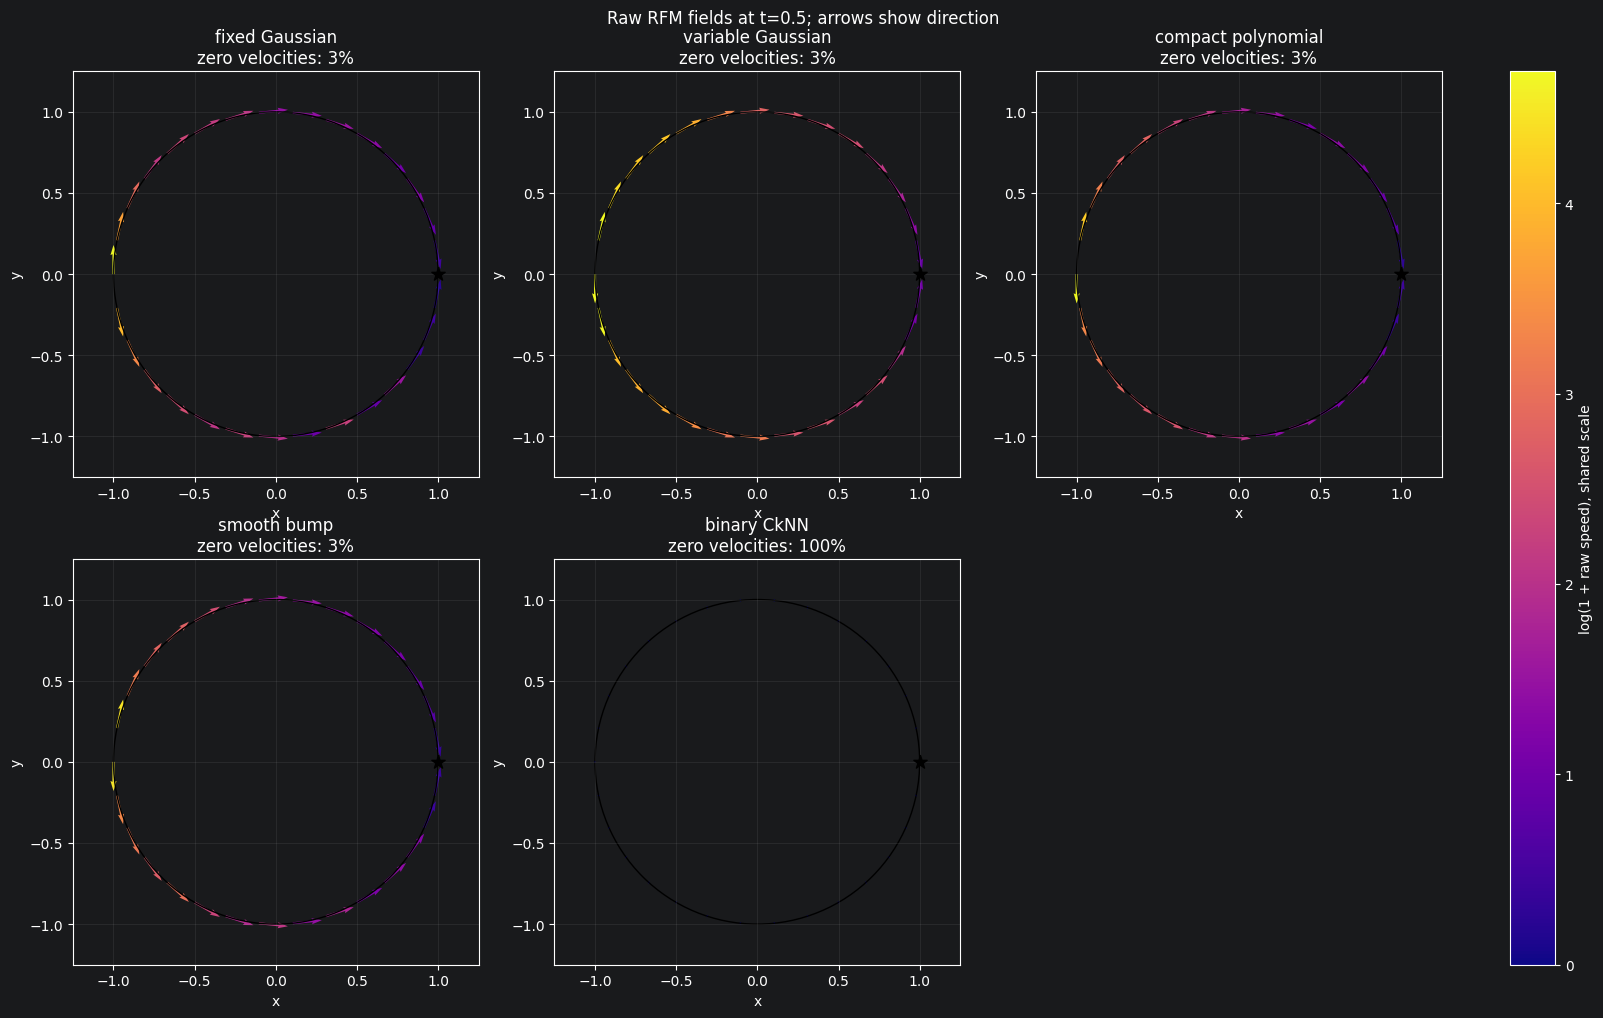

In [6]:
kernel_field_angles = np.linspace(0.0, 2.0 * np.pi, 30, endpoint=False)
kernel_field_points = radius * np.column_stack((
    np.cos(kernel_field_angles), np.sin(kernel_field_angles),
)).astype(np.float32)
kernel_target = np.array([radius, 0.0], dtype=np.float32)
kernel_field_targets = np.broadcast_to(kernel_target, kernel_field_points.shape)
kernel_field_time = 0.5
kernel_fields = {}
kernel_field_rows = []
kernel_raw_interpolators = {}

for kernel_name, model in kernel_models.items():
    interpolator = RFMInterpolation(model, project_to_manifold=False)
    kernel_raw_interpolators[kernel_name] = interpolator
    velocities = np.asarray(jax.jit(interpolator.u_t)(
        jnp.asarray(kernel_field_points), jnp.asarray(kernel_field_targets), kernel_field_time
    ))
    if not np.all(np.isfinite(velocities)):
        raise ValueError(f"Non-finite vector field for {kernel_name}.")
    speeds = np.linalg.norm(velocities, axis=1)
    support_counts = np.asarray(jax.jit(jax.vmap(
        lambda point: jnp.count_nonzero(kernel_fitted[kernel_name](point))
    ))(jnp.asarray(kernel_field_points)))
    with jax.enable_x64():
        gradient_query = radius * jnp.array([np.cos(0.11), np.sin(0.11)], dtype=jnp.float64)
        gradient_target = jnp.asarray(kernel_target, dtype=jnp.float64)

        def checked_distance(point):
            residual = model.extend_point(point) - model.extend_point(gradient_target)
            return jnp.sqrt(jnp.dot(residual, residual) + model.eps)

        _, analytic_gradient, _ = model.distance_grad_and_norm(
            gradient_query, gradient_target
        )
        autodiff_gradient = jax.grad(checked_distance)(gradient_query)
        difference_step = 1e-6
        finite_difference_gradient = np.array([
            (float(checked_distance(gradient_query + direction))
             - float(checked_distance(gradient_query - direction))) / (2.0 * difference_step)
            for direction in np.eye(2) * difference_step
        ])
        gradient_scale = max(float(jnp.linalg.norm(analytic_gradient)), 1e-10)
        autodiff_error = float(jnp.linalg.norm(
            analytic_gradient - autodiff_gradient
        )) / gradient_scale
        finite_difference_error = float(np.linalg.norm(
            np.asarray(analytic_gradient) - finite_difference_gradient
        )) / gradient_scale
    if autodiff_error > 1e-5:
        raise AssertionError(f"{kernel_name}: analytic/autodiff gradient mismatch.")
    probe_velocities = np.asarray(jax.jit(interpolator.u_t)(
        jnp.asarray(circle_probe_points),
        jnp.broadcast_to(jnp.asarray(kernel_target), circle_probe_points.shape),
        kernel_field_time,
    ))
    kernel_fields[kernel_name] = velocities
    kernel_field_rows.append({
        "kernel": kernel_name,
        "median_speed": np.median(speeds),
        "p95_speed": np.quantile(speeds, 0.95),
        "zero_speed_fraction": np.mean(speeds < 1e-8),
        "unsupported_probe_fraction": np.mean(support_counts == 0),
        "radial_velocity_fraction": np.mean(
            np.abs(np.sum(probe_velocities * circle_probe_normals, axis=1)) > 1e-6
        ),
        "autodiff_relative_error": autodiff_error,
        "finite_difference_relative_error": finite_difference_error,
    })

kernel_field_df = pd.DataFrame(kernel_field_rows).set_index("kernel")
display(kernel_field_df)

def style_kernel_circle(axis):
    axis.add_patch(plt.Circle((0, 0), radius, fill=False, color="black"))
    axis.scatter(*kernel_target, s=100, marker="*", color="black", zorder=5)
    axis.set(xlim=(-plot_limit, plot_limit), ylim=(-plot_limit, plot_limit), xlabel="x", ylabel="y")
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.15)

kernel_speed_colors = np.concatenate([
    np.log1p(np.linalg.norm(velocities, axis=1))
    for velocities in kernel_fields.values()
])
kernel_color_max = max(float(np.quantile(kernel_speed_colors, 0.98)), 1e-6)
fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
for axis, (kernel_name, velocities) in zip(axes.ravel(), kernel_fields.items()):
    speeds = np.linalg.norm(velocities, axis=1)
    directions = 0.18 * velocities / np.maximum(speeds[:, None], 1e-8)
    quiver = axis.quiver(
        kernel_field_points[:, 0], kernel_field_points[:, 1],
        directions[:, 0], directions[:, 1], np.log1p(speeds),
        cmap="plasma", clim=(0.0, kernel_color_max),
        angles="xy", scale_units="xy", scale=1, width=0.005,
    )
    style_kernel_circle(axis)
    axis.set_title(f"{kernel_name}\nzero velocities: {np.mean(speeds < 1e-8):.0%}")
for axis in axes.ravel()[len(kernel_fields):]:
    axis.set_visible(False)
fig.colorbar(quiver, ax=list(axes.ravel()), label="log(1 + raw speed), shared scale")
fig.suptitle("Raw RFM fields at t=0.5; arrows show direction")
plt.show()

In [7]:
kernel_start_rng = np.random.default_rng(2026)
kernel_start_ids = kernel_start_rng.choice(len(left_gaussian_points), 12, replace=False)
kernel_starts = left_gaussian_points[kernel_start_ids].astype(np.float32)
kernel_final_time = 0.99
kernel_integration_steps = 800
kernel_step_times = np.linspace(
    0.0, kernel_final_time, kernel_integration_steps + 1, dtype=np.float32
)
kernel_trajectories = {}
kernel_distance_traces = {}
kernel_trajectory_rows = []

def integrate_kernel_paths(model, guarded, steps=None):
    integration_steps = kernel_integration_steps if steps is None else steps
    interpolator = (
        TangentSafeCircleRFMInterpolation(
            model, projection_fn=project_to_circle, project_to_manifold=False
        )
        if guarded else RFMInterpolation(model, project_to_manifold=False)
    )
    targets = jnp.broadcast_to(jnp.asarray(kernel_target), kernel_starts.shape)
    time_step = kernel_final_time / integration_steps
    integration_times = np.linspace(
        0.0, kernel_final_time, integration_steps + 1, dtype=np.float32
    )

    def integrate(starts):
        def step(state, current_time):
            velocities = interpolator.u_t(state, targets, current_time)
            proposed = state + time_step * velocities
            next_state = interpolator.project(proposed)
            return next_state, (next_state, proposed)

        _, (path, proposed_path) = jax.lax.scan(
            step, starts, jnp.asarray(integration_times[:-1])
        )
        return jnp.concatenate((starts[None], path), axis=0), proposed_path

    return jax.jit(integrate)(jnp.asarray(kernel_starts))

def kernel_path_geometry(path):
    segment_starts = path[:-1]
    segments = np.diff(path, axis=0)
    segment_lengths_sq = np.sum(segments**2, axis=-1)
    closest_fractions = np.clip(
        -np.sum(segment_starts * segments, axis=-1)
        / np.maximum(segment_lengths_sq, 1e-20), 0.0, 1.0
    )
    closest_points = segment_starts + closest_fractions[..., None] * segments
    closest_radii = np.linalg.norm(closest_points, axis=-1)
    radii = np.linalg.norm(path, axis=-1)
    return {
        "max_step_length": np.sqrt(segment_lengths_sq.max()),
        "max_segment_hole_penetration": np.maximum(radius - closest_radii, 0.0).max(),
        "hole_crossing_segment_fraction": np.mean(closest_radii < radius - 1e-3),
        "max_domain_violation": np.maximum(
            np.maximum(radius - radii, 0.0),
            np.maximum(radii - radius, 0.0),
        ).max(),
    }

for kernel_name, model in kernel_models.items():
    for mode, guarded in [("unprojected", False), ("circle + tangent", True)]:
        integration_started = time.perf_counter()
        path, proposed_path = integrate_kernel_paths(model, guarded)
        path = np.asarray(path)
        proposed_path = np.asarray(proposed_path)
        if not np.all(np.isfinite(path)):
            raise ValueError(f"Non-finite trajectories for {kernel_name}, {mode}.")
        sampled_path = path[::8]
        sampled_targets = np.broadcast_to(kernel_target, sampled_path.shape)
        spectral_distances = np.asarray(jax.jit(lambda states: jax.lax.map(
            lambda batch: model.distance_grad_and_norm_batch(
                batch, jnp.asarray(sampled_targets[0])
            )[0], states
        ))(jnp.asarray(sampled_path)))
        radii = np.linalg.norm(path, axis=-1)
        violation = np.maximum(radius - radii, 0.0) + np.maximum(radii - radius, 0.0)
        proposed_radii = np.linalg.norm(proposed_path, axis=-1)
        proposed_violation = (
            np.maximum(radius - proposed_radii, 0.0)
            + np.maximum(proposed_radii - radius, 0.0)
        )
        final_errors = np.linalg.norm(path[-1] - kernel_target, axis=1)
        initial_errors = np.linalg.norm(path[0] - kernel_target, axis=1)
        path_lengths = np.linalg.norm(np.diff(path, axis=0), axis=-1).sum(axis=0)
        unsupported_final = np.asarray(jax.jit(jax.vmap(
            lambda point: jnp.count_nonzero(kernel_fitted[kernel_name](point)) == 0
        ))(jnp.asarray(path[-1])))
        kernel_trajectories[kernel_name, mode] = path
        kernel_distance_traces[kernel_name, mode] = spectral_distances
        kernel_trajectory_rows.append({
            "kernel": kernel_name,
            "mode": mode,
            "mean_final_euclidean": np.mean(final_errors),
            "p90_final_euclidean": np.quantile(final_errors, 0.9),
            "mean_relative_euclidean": np.mean(final_errors / initial_errors),
            "fraction_within_0.1": np.mean(final_errors < 0.1),
            "mean_final_relative_spectral": np.mean(
                spectral_distances[-1] / np.maximum(spectral_distances[0], 1e-12)
            ),
            "mean_path_length": np.mean(path_lengths),
            "max_circle_violation": np.max(violation),
            "max_proposed_violation": np.max(proposed_violation),
            "unsupported_final_fraction": np.mean(unsupported_final),
            "integration_seconds": time.perf_counter() - integration_started,
            **kernel_path_geometry(path),
        })
        print(
            f"{kernel_name}, {mode}: mean endpoint error {np.mean(final_errors):.4f}, "
            f"{np.mean(final_errors < 0.1):.0%} within 0.1; "
            f"{kernel_trajectory_rows[-1]['integration_seconds']:.2f}s",
            flush=True,
        )

kernel_trajectory_df = pd.DataFrame(kernel_trajectory_rows)
display(kernel_trajectory_df.sort_values(["mode", "mean_final_euclidean"]).reset_index(drop=True))

fixed Gaussian, unprojected: mean endpoint error 0.3591, 83% within 0.1; 11.92s
fixed Gaussian, circle + tangent: mean endpoint error 0.0262, 100% within 0.1; 17.98s
variable Gaussian, unprojected: mean endpoint error 0.5174, 83% within 0.1; 12.18s
variable Gaussian, circle + tangent: mean endpoint error 0.0000, 100% within 0.1; 18.15s
compact polynomial, unprojected: mean endpoint error 0.0146, 100% within 0.1; 10.65s
compact polynomial, circle + tangent: mean endpoint error 0.0145, 100% within 0.1; 16.43s
smooth bump, unprojected: mean endpoint error 0.1819, 92% within 0.1; 11.25s
smooth bump, circle + tangent: mean endpoint error 0.0133, 100% within 0.1; 17.26s
binary CkNN, unprojected: mean endpoint error 1.9944, 0% within 0.1; 11.28s
binary CkNN, circle + tangent: mean endpoint error 1.9944, 0% within 0.1; 17.32s


,kernel,mode,mean_final_euclidean,p90_final_euclidean,mean_relative_euclidean,fraction_within_0.1,mean_final_relative_spectral,mean_path_length,max_circle_violation,max_proposed_violation,unsupported_final_fraction,integration_seconds,max_step_length,max_segment_hole_penetration,hole_crossing_segment_fraction,max_domain_violation
0,variable Gaussian,circle + tangent,0.000040,0.000044,0.000020,1.000000,0.000007,3.004049,1.192093e-07,2.855860e+00,0.000000,18.147551,1.217090,2.064808e-01,0.001042,1.192093e-07
1,smooth bump,circle + tangent,0.013318,0.013393,0.006678,1.000000,0.008951,2.998396,1.192093e-07,1.122426e-01,0.000000,17.257469,0.449256,2.555543e-02,0.000208,1.192093e-07
2,compact polynomial,circle + tangent,0.014504,0.014897,0.007272,1.000000,0.009731,2.997523,1.192093e-07,9.360909e-03,0.000000,16.431328,0.136192,2.321243e-03,0.000104,1.192093e-07
3,fixed Gaussian,circle + tangent,0.026161,0.030279,0.013118,1.000000,0.009866,2.993800,1.192093e-07,7.169104e-02,0.000000,17.979054,0.365774,1.686609e-02,0.000417,1.192093e-07
4,binary CkNN,circle + tangent,1.994435,1.999681,1.000000,0.000000,1.000000,0.000000,5.960464e-08,5.960464e-08,0.000000,17.320693,0.000000,5.960464e-08,0.000000,5.960464e-08
5,compact polynomial,unprojected,0.014629,0.015087,0.007335,1.000000,0.009700,3.006340,9.158373e-03,9.158373e-03,0.000000,10.650201,0.137148,1.072884e-06,0.000000,9.158373e-03
6,smooth bump,unprojected,0.181897,0.015403,0.091139,0.916667,0.051468,2.805013,1.084477e-01,1.084477e-01,0.083333,11.246976,0.486930,3.761053e-05,0.000000,1.084477e-01
7,fixed Gaussian,unprojected,0.359053,1.806697,0.179621,0.833333,0.247271,2.535722,7.011652e-02,7.011652e-02,0.083333,11.919712,0.385389,9.655952e-06,0.000000,7.011652e-02
8,variable Gaussian,unprojected,0.517391,1.778575,0.259233,0.833333,0.086248,2.941746,2.828594e+00,2.828594e+00,0.166667,12.175358,3.725582,8.121550e-03,0.001458,2.828594e+00
9,binary CkNN,unprojected,1.994435,1.999681,1.000000,0.000000,1.000000,0.000000,5.960464e-08,5.960464e-08,0.000000,11.278797,0.000000,5.960464e-08,0.000000,5.960464e-08


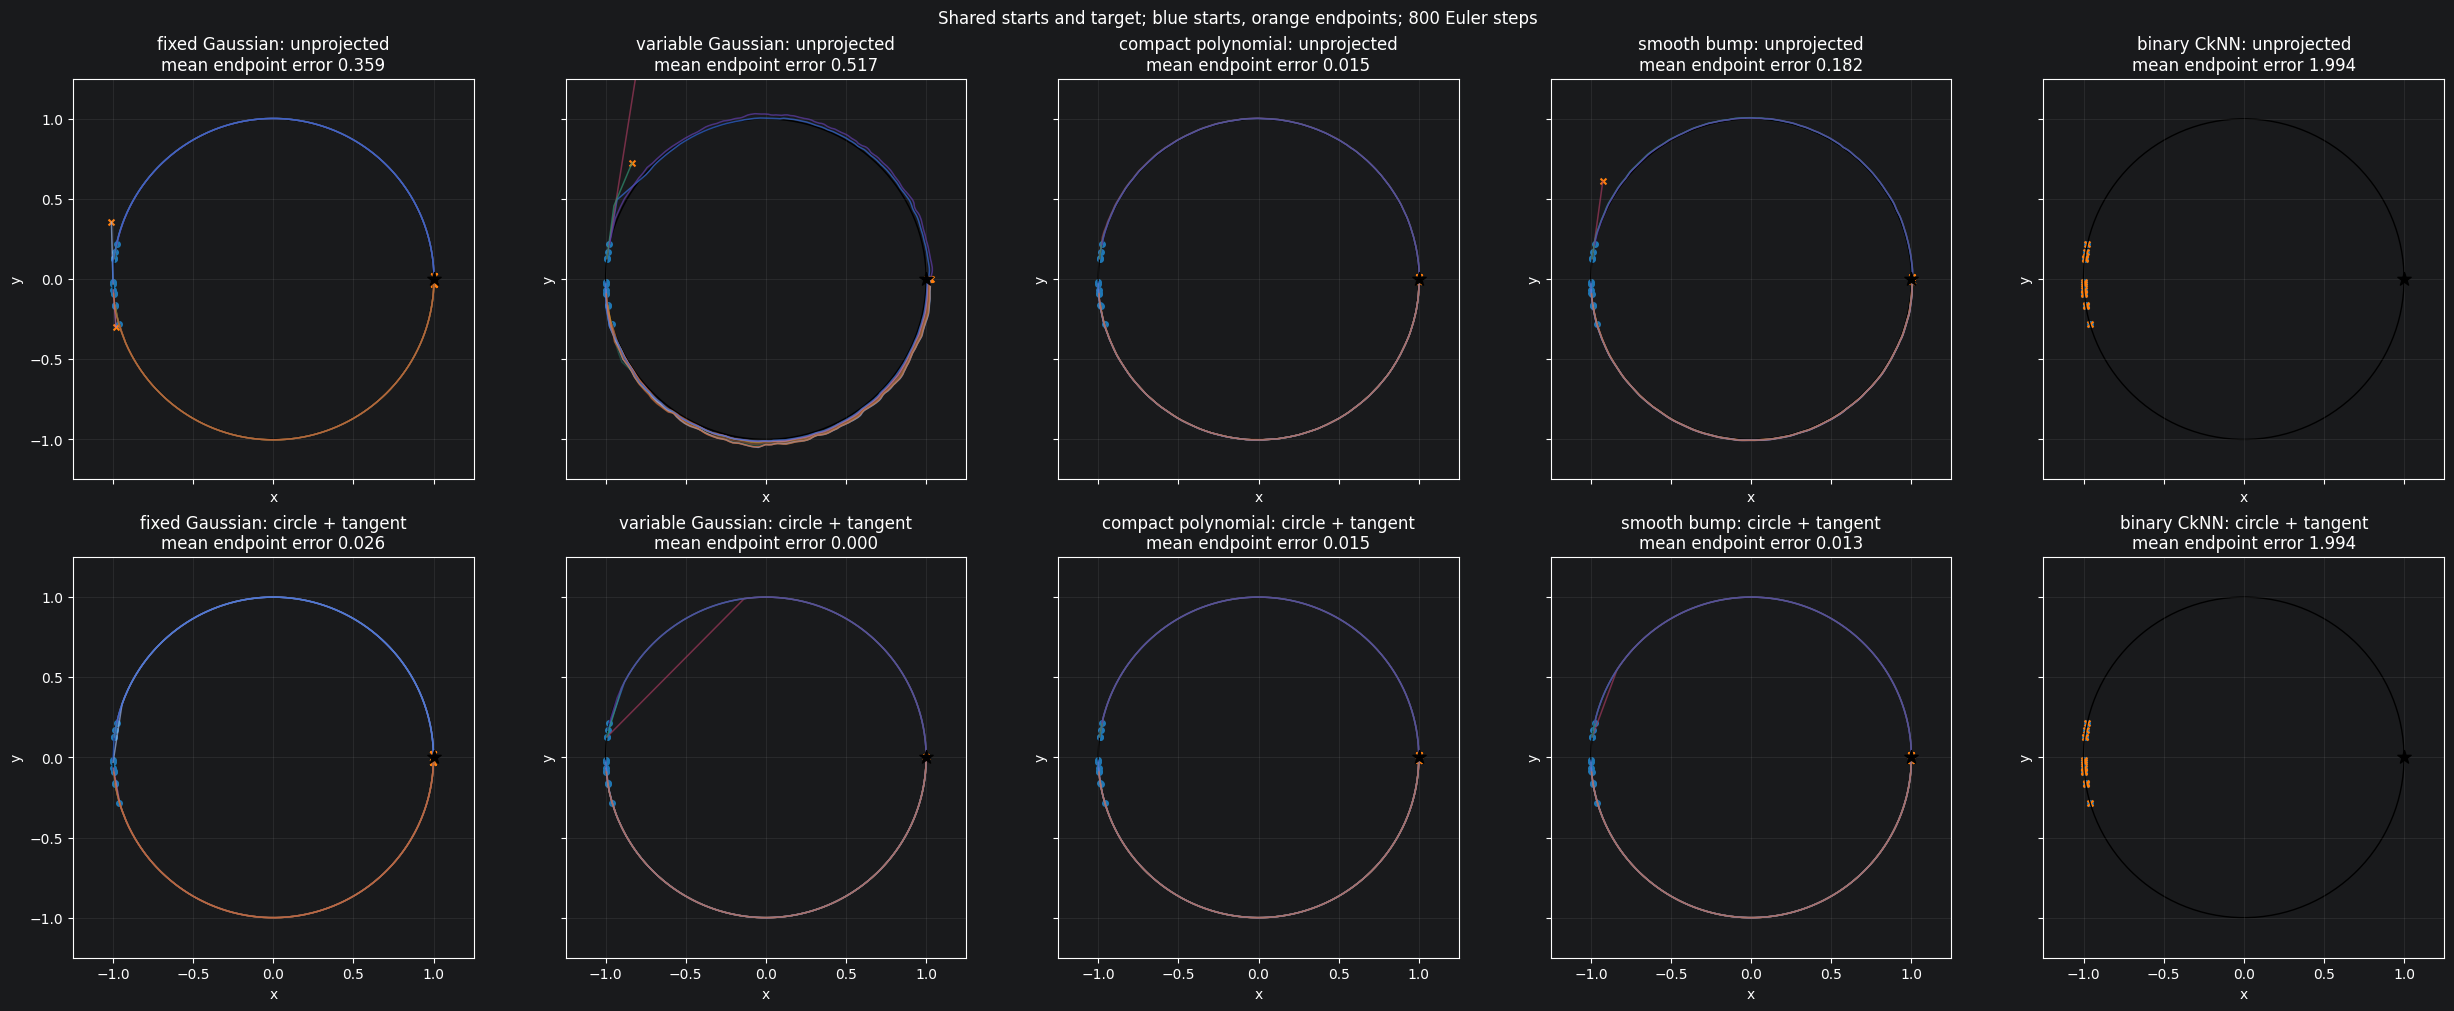

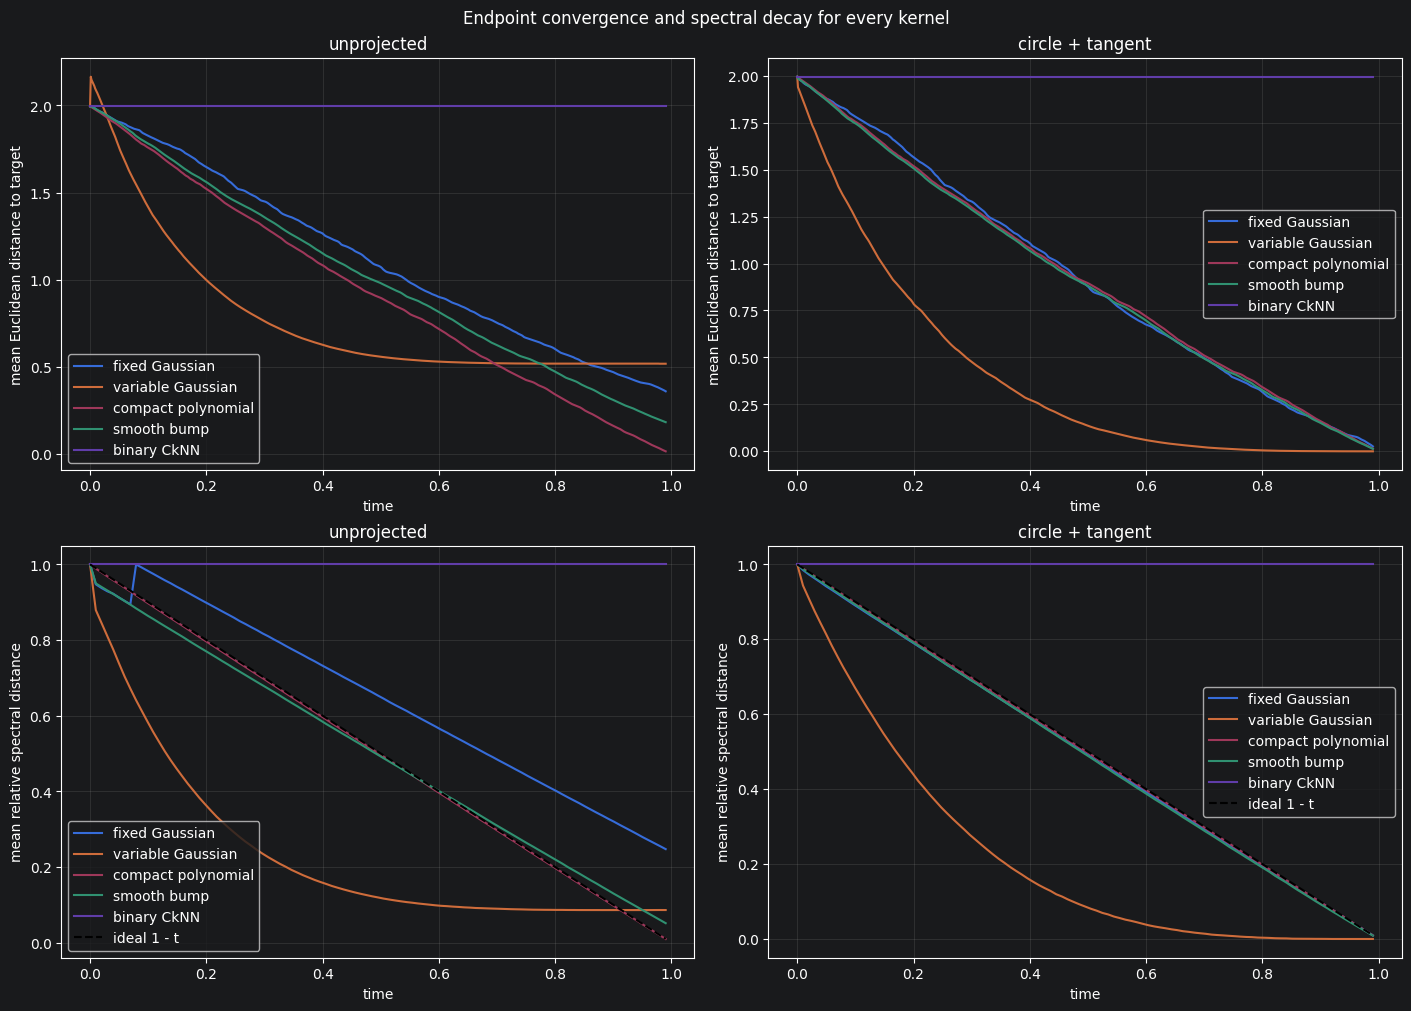

Lowest endpoint error passing domain/segment checks: binary CkNN (1.9944).
Binary CkNN is a graph baseline: its almost-everywhere zero gradients leave the moving-point interpolation stationary.
Circle projection enforces the domain. Compare the raw radial-field diagnostic and unprojected paths to assess the pre-metric itself.


In [8]:
fig, axes = plt.subplots(
    2, len(kernel_models), figsize=(25, 10), sharex=True, sharey=True,
    constrained_layout=True,
)
for column, kernel_name in enumerate(kernel_models):
    for row, mode in enumerate(["unprojected", "circle + tangent"]):
        axis = axes[row, column]
        path = kernel_trajectories[kernel_name, mode]
        for start_index in range(len(kernel_starts)):
            axis.plot(path[:, start_index, 0], path[:, start_index, 1], linewidth=1.1, alpha=0.7)
        axis.scatter(kernel_starts[:, 0], kernel_starts[:, 1], s=16, color="tab:blue")
        axis.scatter(path[-1, :, 0], path[-1, :, 1], s=18, color="tab:orange", marker="x")
        style_kernel_circle(axis)
        result_row = kernel_trajectory_df[
            kernel_trajectory_df["kernel"].eq(kernel_name)
            & kernel_trajectory_df["mode"].eq(mode)
        ].iloc[0]
        axis.set_title(
            f"{kernel_name}: {mode}\n"
            f"mean endpoint error {result_row['mean_final_euclidean']:.3f}"
        )
fig.suptitle(
    f"Shared starts and target; blue starts, orange endpoints; {kernel_integration_steps} Euler steps"
)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for column, mode in enumerate(["unprojected", "circle + tangent"]):
    for kernel_name in kernel_models:
        path = kernel_trajectories[kernel_name, mode]
        ambient_errors = np.linalg.norm(path - kernel_target, axis=-1)
        axes[0, column].plot(
            kernel_step_times, ambient_errors.mean(axis=1), label=kernel_name
        )
        distances = kernel_distance_traces[kernel_name, mode]
        axes[1, column].plot(
            kernel_step_times[::8],
            (distances / np.maximum(distances[0], 1e-12)).mean(axis=1),
            label=kernel_name,
        )
    axes[0, column].set(
        title=mode, xlabel="time", ylabel="mean Euclidean distance to target"
    )
    axes[1, column].plot(
        kernel_step_times, 1.0 - kernel_step_times, "k--", label="ideal 1 - t"
    )
    axes[1, column].set(
        title=mode, xlabel="time", ylabel="mean relative spectral distance"
    )
    axes[0, column].legend()
    axes[1, column].legend()
    axes[0, column].grid(alpha=0.2)
    axes[1, column].grid(alpha=0.2)
fig.suptitle("Endpoint convergence and spectral decay for every kernel")
plt.show()

guarded_kernel_results = kernel_trajectory_df[
    kernel_trajectory_df["mode"].eq("circle + tangent")
].sort_values("mean_final_euclidean")
valid_guarded_results = guarded_kernel_results[
    guarded_kernel_results["max_segment_hole_penetration"].le(1e-3)
    & guarded_kernel_results["max_domain_violation"].le(1e-3)
    & guarded_kernel_results["unsupported_final_fraction"].eq(0.0)
]
if len(valid_guarded_results):
    best_kernel_result = valid_guarded_results.iloc[0]
    print(
        f"Lowest endpoint error passing domain/segment checks: {best_kernel_result['kernel']} "
        f"({best_kernel_result['mean_final_euclidean']:.4f})."
    )
print(
    "Binary CkNN is a graph baseline: its almost-everywhere zero gradients "
    "leave the moving-point interpolation stationary."
)
print(
    "Circle projection enforces the domain. Compare the raw radial-field "
    "diagnostic and unprojected paths to assess the pre-metric itself."
)

fixed Gaussian, 1600 guarded steps: mean endpoint error 0.0263; maximum hole penetration 0.0045
variable Gaussian, 1600 guarded steps: mean endpoint error 0.0000; maximum hole penetration 0.1418
compact polynomial, 1600 guarded steps: mean endpoint error 0.0147; maximum hole penetration 0.0006
smooth bump, 1600 guarded steps: mean endpoint error 0.0139; maximum hole penetration 0.0071
binary CkNN, 1600 guarded steps: mean endpoint error 1.9944; maximum hole penetration 0.0000


,coarse_mean_endpoint_error,refined_mean_endpoint_error,mean_endpoint_shift,refined_fraction_within_0.1,passes_domain_segment_checks,max_step_length,max_segment_hole_penetration,hole_crossing_segment_fraction,max_domain_violation,refinement_seconds
kernel,,,,,,,,,,
fixed Gaussian,0.026161,0.026322,0.000169,1.0,False,0.190072,4.526198e-03,0.000104,1.192093e-07,31.782197
variable Gaussian,0.000040,0.000041,0.000001,1.0,False,1.026502,1.417614e-01,0.000156,1.192093e-07,30.644754
compact polynomial,0.014504,0.014678,0.000203,1.0,True,0.068453,5.859137e-04,0.000000,1.192093e-07,31.532886
smooth bump,0.013318,0.013881,0.000563,1.0,False,0.238243,7.120371e-03,0.000052,1.192093e-07,33.239678
binary CkNN,1.994435,1.994435,0.000000,0.0,True,0.000000,5.960464e-08,0.000000,5.960464e-08,29.949886


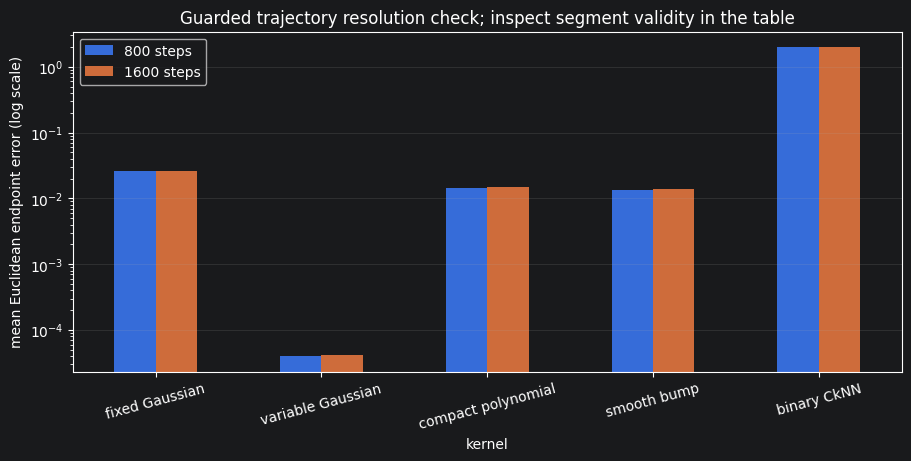

In [9]:
kernel_refinement_steps = 2 * kernel_integration_steps
kernel_refinement_rows = []
kernel_refined_trajectories = {}

for kernel_name, model in kernel_models.items():
    refinement_started = time.perf_counter()
    refined_path, _ = integrate_kernel_paths(
        model, guarded=True, steps=kernel_refinement_steps
    )
    refined_path = np.asarray(refined_path)
    if not np.all(np.isfinite(refined_path)):
        raise ValueError(f"{kernel_name}: non-finite refined trajectories.")
    refined_errors = np.linalg.norm(refined_path[-1] - kernel_target, axis=1)
    coarse_path = kernel_trajectories[kernel_name, "circle + tangent"]
    coarse_errors = np.linalg.norm(coarse_path[-1] - kernel_target, axis=1)
    geometry = kernel_path_geometry(refined_path)
    kernel_refined_trajectories[kernel_name] = refined_path
    kernel_refinement_rows.append({
        "kernel": kernel_name,
        "coarse_mean_endpoint_error": np.mean(coarse_errors),
        "refined_mean_endpoint_error": np.mean(refined_errors),
        "mean_endpoint_shift": np.linalg.norm(
            refined_path[-1] - coarse_path[-1], axis=1
        ).mean(),
        "refined_fraction_within_0.1": np.mean(refined_errors < 0.1),
        "passes_domain_segment_checks": (
            geometry["max_domain_violation"] <= 1e-3
            and geometry["max_segment_hole_penetration"] <= 1e-3
        ),
        **geometry,
        "refinement_seconds": time.perf_counter() - refinement_started,
    })
    print(
        f"{kernel_name}, {kernel_refinement_steps} guarded steps: "
        f"mean endpoint error {np.mean(refined_errors):.4f}; "
        f"maximum hole penetration {geometry['max_segment_hole_penetration']:.4f}",
        flush=True,
    )

kernel_refinement_df = pd.DataFrame(kernel_refinement_rows).set_index("kernel")
display(kernel_refinement_df)

fig, axis = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
kernel_error_comparison = kernel_refinement_df[[
    "coarse_mean_endpoint_error", "refined_mean_endpoint_error"
]].rename(columns={
    "coarse_mean_endpoint_error": f"{kernel_integration_steps} steps",
    "refined_mean_endpoint_error": f"{kernel_refinement_steps} steps",
})
kernel_error_comparison.plot.bar(ax=axis, rot=15, logy=True)
axis.set_ylabel("mean Euclidean endpoint error (log scale)")
axis.set_title("Guarded trajectory resolution check; inspect segment validity in the table")
axis.grid(axis="y", alpha=0.2)
plt.show()

The fields use a shared color scale and direction-normalized arrows. The two trajectory rows separate the raw field from a common circle projection and tangent-space guard. Projection can keep a poor field on the circle, so read endpoint errors together with the raw radial-velocity diagnostic and unprojected paths. Unsupported queries are reported explicitly. The segment diagnostic also checks the closest point to the origin along each Euler segment: projecting endpoints alone can still allow a step through the disk. A penetration tolerance of $10^{-3}$ accounts for small circle chords and floating-point error.

Raw spectral distances have different scales across profiles; the decay plot therefore normalizes each path by its own initial distance. Euclidean endpoint error compares target convergence in the common circle coordinates. Compare the coarse and refined runs before interpreting a small endpoint error as convergence of the field ODE. These are deterministic toy comparisons on uniformly sampled construction points, not a density-robustness benchmark.

The fitted extensions, kernels, graphs, trajectories, and refinement results are available in kernel_models, kernel_fitted, kernel_graphs, kernel_trajectories, and kernel_refinement_df, indexed by the profile labels used in the plots.

## Train CellFlow RFM between the two Gaussian clouds

The left Gaussian is the source/control distribution and the right Gaussian is the target. The selected model from `kernel_models` supplies the same biharmonic geometry to OT matching and RFM interpolation:

$$c(x,y)=d_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2,\qquad \Psi_k(x)=\phi_k(x)/(\lambda_k+10^{-8}).$$

`match_biharmonic` evaluates the continuous Nyström embedding and calls the existing `cellflow.utils.match_linear` with the **unsquared** embedding distance. The standard `CellFlow(..., solver="otrfm") → prepare_data → prepare_model → train → predict` workflow keeps all cell coordinates two-dimensional and samples pairs from the OT coupling on each training batch. This is a linear OT problem with a manifold-aware cost.

Run the data-generation, construction, circle-helper, and kernel-fit cells above first. The kernel comparison plots are optional. The compact network and training settings below suit this toy example. OT uses mean cost scaling, so `rfm_ot_epsilon` is relative to the batch's mean biharmonic cost. Training interpolation projects to the circle; standard model prediction is unconstrained, and the evaluation reports its domain violations. Evaluation uses the fitted clouds and measures reconstruction, not generalization.

In [20]:
import anndata as ad
import optax
from ott.geometry import costs
from scipy.spatial.distance import cdist

from cellflow.model import CellFlow
from cellflow.utils import match_linear

rfm_kernel_name = "compact polynomial"
rfm_nystroem = kernel_models[rfm_kernel_name]
rfm_ot_epsilon = 0.05
rfm_batch_size = 32
rfm_interpolation_steps = 32
rfm_num_iterations = 300
rfm_seed = 2026

rfm_source = left_gaussian_points.astype(np.float32)
rfm_target = right_gaussian_points.astype(np.float32)
assert kernel_spectral_weight_type == "biharmonic"
assert rfm_source.shape[1] == rfm_target.shape[1] == 2
assert np.all(np.isfinite(rfm_source)) and np.all(np.isfinite(rfm_target))
assert np.all(in_circle(rfm_source)) and np.all(in_circle(rfm_target))

# Embed each batch once, then let OTT form its pairwise cost matrix.
# Euclidean distance in these weighted coordinates IS biharmonic distance.
rfm_embed = jax.jit(jax.vmap(rfm_nystroem.extend_point))


def match_biharmonic(source_batch, target_batch):
    return match_linear(
        rfm_embed(jnp.asarray(source_batch)),
        rfm_embed(jnp.asarray(target_batch)),
        cost_fn=costs.Euclidean(),
        epsilon=rfm_ot_epsilon,
        scale_cost="mean",
        tau_a=1.0,
        tau_b=1.0,
        threshold=1e-5,
        max_iterations=5000,
    )


rfm_match_jit = jax.jit(match_biharmonic)
print(f"Geometry: {rfm_kernel_name}, {rfm_nystroem.Psi.shape[1]} biharmonic modes")
print(f"Source: {rfm_source.shape}; target: {rfm_target.shape}")
print(f"Batch size: {rfm_batch_size}; interpolation steps: {rfm_interpolation_steps}")
print(f"OT cost: unsquared biharmonic distance; relative epsilon: {rfm_ot_epsilon}")

Geometry: compact polynomial, 32 biharmonic modes
Source: (250, 2); target: (250, 2)
Batch size: 32; interpolation steps: 32
OT cost: unsquared biharmonic distance; relative epsilon: 0.05


,coupling diagnostics
coupling_mass,9.999995e-01
max_source_marginal_error,4.190952e-09
max_target_marginal_error,7.450581e-09
OT_mean_biharmonic_cost,5.092525e+01
independent_mean_biharmonic_cost,5.098414e+01


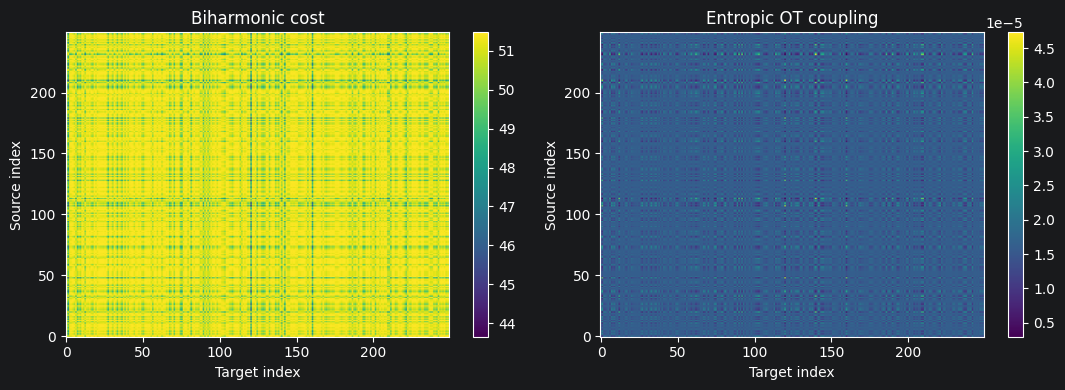

In [21]:
# Full-cloud diagnostic; training recomputes the coupling for each sampled batch.
rfm_source_embedding = np.asarray(rfm_embed(jnp.asarray(rfm_source)))
rfm_target_embedding = np.asarray(rfm_embed(jnp.asarray(rfm_target)))
rfm_cost_matrix = cdist(rfm_source_embedding, rfm_target_embedding)
rfm_coupling = np.asarray(rfm_match_jit(rfm_source, rfm_target))

assert rfm_coupling.shape == (len(rfm_source), len(rfm_target))
assert np.all(np.isfinite(rfm_coupling)) and np.all(rfm_coupling >= 0)
np.testing.assert_allclose(rfm_coupling.sum(axis=1), 1 / len(rfm_source), atol=5e-5)
np.testing.assert_allclose(rfm_coupling.sum(axis=0), 1 / len(rfm_target), atol=5e-5)

# Check that the OT cost agrees with the distance used by RFM.
rfm_check_distances = np.asarray(jax.jit(
    rfm_nystroem.distance_grad_and_norm_batch
)(jnp.asarray(rfm_source[:8]), jnp.asarray(rfm_target[:8]))[0])
np.testing.assert_allclose(
    np.diag(rfm_cost_matrix[:8, :8]), rfm_check_distances, rtol=1e-5, atol=1e-6
)
# A reordered, rectangular batch also works without global point indices.
rfm_rectangular_coupling = np.asarray(
    rfm_match_jit(rfm_source[7:0:-1], rfm_target[2:11])
)
assert rfm_rectangular_coupling.shape == (7, 9)
assert np.all(np.isfinite(rfm_rectangular_coupling))

display(pd.DataFrame({
    "coupling_mass": rfm_coupling.sum(),
    "max_source_marginal_error": np.max(np.abs(rfm_coupling.sum(axis=1) - 1 / len(rfm_source))),
    "max_target_marginal_error": np.max(np.abs(rfm_coupling.sum(axis=0) - 1 / len(rfm_target))),
    "OT_mean_biharmonic_cost": np.sum(rfm_coupling * rfm_cost_matrix),
    "independent_mean_biharmonic_cost": rfm_cost_matrix.mean(),
}, index=["coupling diagnostics"]).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in [
    (axes[0], rfm_cost_matrix, "Biharmonic cost"),
    (axes[1], rfm_coupling, "Entropic OT coupling"),
]:
    image = ax.imshow(values, aspect="auto", origin="lower")
    ax.set(xlabel="Target index", ylabel="Source index", title=title)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

In [22]:
# AnnData contains only the two Gaussian clouds; the uniform circle is geometry.
rfm_n_source = len(rfm_source)
rfm_adata = ad.AnnData(
    X=np.vstack((rfm_source, rfm_target)),
    obs=pd.DataFrame(
        {
            "control": np.r_[np.ones(rfm_n_source, dtype=bool), np.zeros(len(rfm_target), dtype=bool)],
            "right_gaussian": np.r_[np.zeros(rfm_n_source, dtype=bool), np.ones(len(rfm_target), dtype=bool)],
        },
        index=[f"toy_{i}" for i in range(rfm_n_source + len(rfm_target))],
    ),
)

rfm_cf = CellFlow(rfm_adata, solver="otrfm")
rfm_cf.prepare_data(
    sample_rep="X",
    control_key="control",
    perturbation_covariates={"transport": ["right_gaussian"]},
)
rfm_cf.prepare_model(
    match_fn=match_biharmonic,
    nystroem=rfm_nystroem,
    condition_mode="deterministic",
    pooling="mean",
    layers_before_pool=[],
    layers_after_pool=[],
    condition_embedding_dim=16,
    cond_output_dropout=0.0,
    time_freqs=16,
    time_encoder_dims=(32, 32),
    hidden_dims=(64, 64),
    decoder_dims=(64, 64),
    conditioning_kwargs={},
    optimizer=optax.adam(1e-3),
    solver_kwargs={
        "interpolation_steps": rfm_interpolation_steps,
        "projection_fn": project_to_circle,
        "project_to_manifold": False,
        "max_velocity_norm": 30.0,
    },
    seed=rfm_seed,
)

# The default dataloader must see left as source and right as target.
from cellflow.data._dataloader import TrainSampler

rfm_probe_batch = TrainSampler(rfm_cf.train_data, batch_size=rfm_batch_size).sample(
    np.random.default_rng(rfm_seed)
)
assert np.all(np.asarray(rfm_probe_batch["src_cell_data"])[:, 0] < 0)
assert np.all(np.asarray(rfm_probe_batch["tgt_cell_data"])[:, 0] > 0)
print("Solver:", type(rfm_cf.solver).__name__)
print("Coordinate dimensions:", rfm_cf.train_data.cell_data.shape[1])
print("Conditions:", rfm_cf.train_data.condition_data)

[########################################] | 100% Completed | 102.52 ms
[########################################] | 100% Completed | 101.00 ms
Solver: OTRFlowMatching
Coordinate dimensions: 2
Conditions: {'transport': array([[[1.]]])}


In [23]:
# Baseline: leave the source cloud unchanged.
# These empirical distribution metrics do not assume pointwise correspondences.
def rfm_distribution_metrics(samples):
    samples = np.asarray(samples)
    energy = (
        2 * cdist(samples, rfm_target).mean()
        - cdist(samples, samples).mean()
        - cdist(rfm_target, rfm_target).mean()
    )
    return {
        "energy_distance_squared": float(max(energy, 0.0)),
        "mean_error_to_target": float(np.linalg.norm(samples.mean(axis=0) - rfm_target.mean(axis=0))),
        "outside_circle_fraction": float(np.mean(~in_circle(samples))),
    }


rfm_baseline_metrics = rfm_distribution_metrics(rfm_source)
print("Unchanged-source baseline:", rfm_baseline_metrics, flush=True)
rfm_training_started = time.perf_counter()
rfm_cf.train(
    num_iterations=rfm_num_iterations,
    batch_size=rfm_batch_size,
    valid_freq=100,
)
rfm_training_seconds = time.perf_counter() - rfm_training_started
rfm_losses = np.asarray(rfm_cf.trainer.training_logs["loss"])
assert len(rfm_losses) == rfm_num_iterations and np.all(np.isfinite(rfm_losses))
assert rfm_cf.solver.is_trained
print(f"Training finished in {rfm_training_seconds:.1f}s", flush=True)
print(f"Mean loss, first 25: {rfm_losses[:25].mean():.5f}; last 25: {rfm_losses[-25:].mean():.5f}")

Unchanged-source baseline: {'energy_distance_squared': 3.5181065034070813, 'mean_error_to_target': 1.9609367847442627, 'outside_circle_fraction': 0.0}


100%|██████████| 300/300 [04:16<00:00,  1.17it/s, loss=2.48]

Training finished in 256.4s
Mean loss, first 25: 4.48360; last 25: 2.86553


[########################################] | 100% Completed | 101.58 ms
[########################################] | 100% Completed | 101.10 ms


,energy_distance_squared,mean_error_to_target,outside_circle_fraction
unchanged source,3.518107,1.960937,0.0
trained RFM prediction,0.093451,0.115567,1.0


Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.


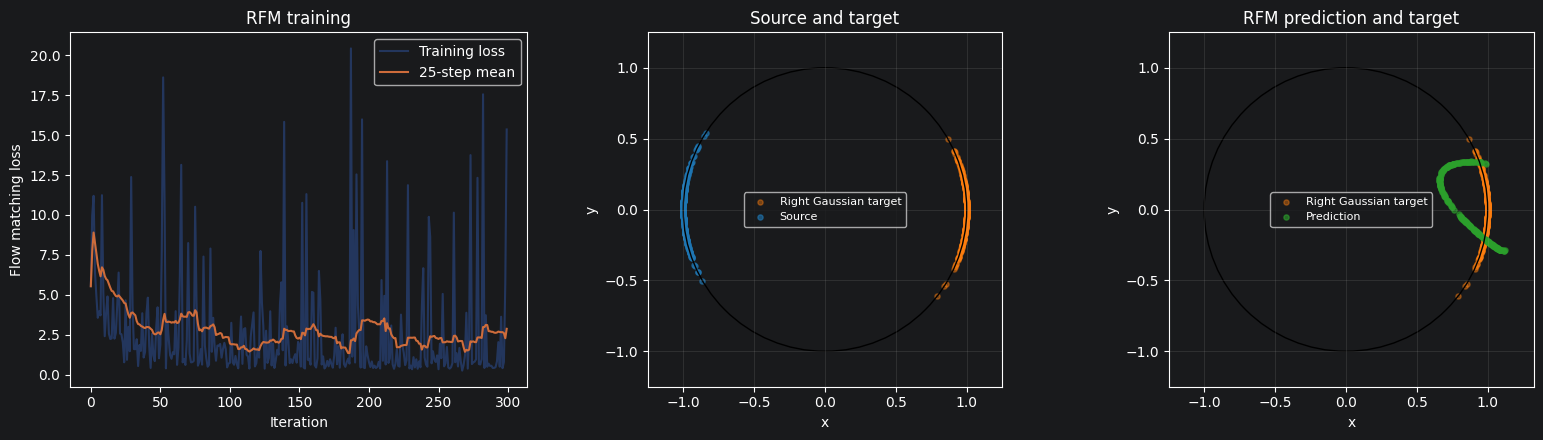

In [24]:
# Use the public prediction API on the left/control cloud.
rfm_source_adata = rfm_adata[rfm_adata.obs["control"]].copy()
rfm_predictions = rfm_cf.predict(
    rfm_source_adata,
    covariate_data=pd.DataFrame({"control": [True], "right_gaussian": [True], "condition": ["right Gaussian"]}),
    condition_id_key="condition",
)
rfm_predicted = np.asarray(rfm_predictions["right Gaussian"])
assert rfm_predicted.shape == rfm_source.shape
assert np.all(np.isfinite(rfm_predicted))
rfm_evaluation = pd.DataFrame(
    [rfm_baseline_metrics, rfm_distribution_metrics(rfm_predicted)],
    index=["unchanged source", "trained RFM prediction"],
)
display(rfm_evaluation)
print("Predictions use the standard unconstrained ODE solver; no endpoint projection is applied.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(rfm_losses, alpha=0.35, label="Training loss")
rfm_smooth_loss = pd.Series(rfm_losses).rolling(25, min_periods=1).mean()
axes[0].plot(rfm_smooth_loss, label="25-step mean")
axes[0].set(xlabel="Iteration", ylabel="Flow matching loss", title="RFM training")
axes[0].legend()
for ax, cloud, title, color in [
    (axes[1], rfm_source, "Source and target", "tab:blue"),
    (axes[2], rfm_predicted, "RFM prediction and target", "tab:green"),
]:
    ax.scatter(rfm_target[:, 0], rfm_target[:, 1], s=14, alpha=0.4, color="tab:orange", label="Right Gaussian target")
    ax.scatter(cloud[:, 0], cloud[:, 1], s=14, alpha=0.6, color=color, label="Source" if ax is axes[1] else "Prediction")
    ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black"))
    ax.set(aspect="equal", xlabel="x", ylabel="y", title=title)
    ax.autoscale_view()
    ax.set_xlim(min(-plot_limit, cloud[:, 0].min() - 0.2), max(plot_limit, cloud[:, 0].max() + 0.2))
    ax.set_ylim(min(-plot_limit, cloud[:, 1].min() - 0.2), max(plot_limit, cloud[:, 1].max() + 0.2))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Reading the training result

The coupling checks verify balanced marginals and agreement between the OT cost and the RFM biharmonic distance. The prediction table compares empirical distributions without assuming a pointwise pairing between the two clouds.

The public `predict` method integrates the learned field with its standard unconstrained ODE solver; `projection_fn` in `solver_kwargs` only projects the training interpolations. Read the distribution metrics together with the fraction of predicted endpoints off the circle. The displayed metrics and plots should be checked again whenever the kernel, regularization, interpolation resolution, or training length changes.

## Inspect the learned vector field at a point and time

Set `rfm_query_point` to the current position $x_t$ and `rfm_field_time` to a time in $[0,1]$, then rerun the cell below. It evaluates $v_	heta(t,x_t\mid\mathrm{right\ Gaussian})$ using the trained inference weights, the same condition as prediction, and dropout disabled.

The colored arrows show the learned field on a circle grid; the red arrow highlights the selected point. Colors encode speed. All arrow lengths equal `arrow_dt` times velocity, so their magnitudes remain comparable. These are instantaneous velocities. The plot uses the field directly, including any radial components.

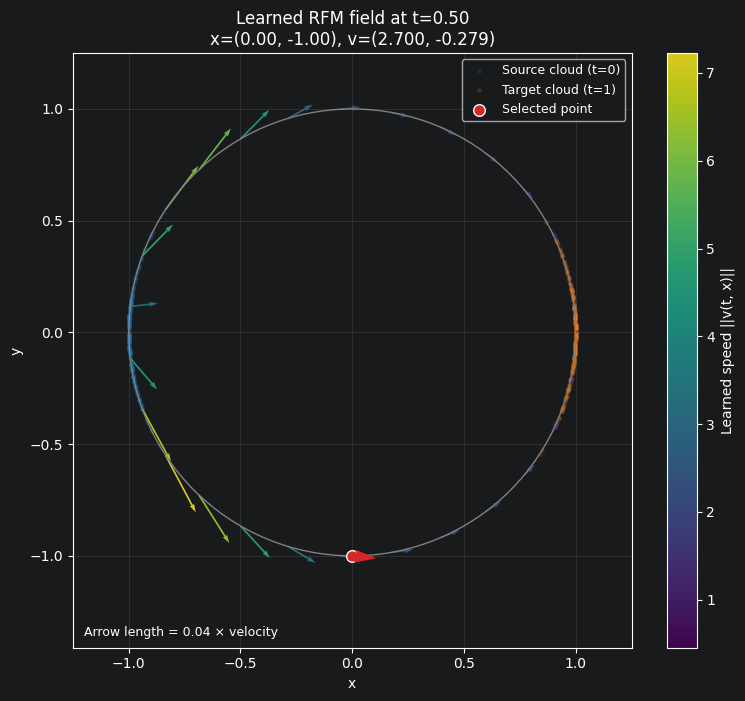

v(t=0.5, x=[0.0, -1.0]) = [ 2.7003024 -0.2788883]
Speed: 2.714666


In [25]:
# Change these two values and rerun this cell.
rfm_query_point = np.array([0, -radius], dtype=np.float32)
rfm_field_time = 0.5


def plot_rfm_learned_field(point, time, grid_size=27, arrow_dt=0.04):
    """Plot the trained instantaneous velocity and highlight v(time, point)."""
    if not rfm_cf.solver.is_trained:
        raise ValueError("Run the RFM training cell first.")
    point = np.asarray(point, dtype=np.float32)
    if point.shape != (2,) or not np.all(np.isfinite(point)):
        raise ValueError("point must contain two finite coordinates.")
    if not np.isfinite(time) or not 0.0 <= time <= 1.0:
        raise ValueError("time must be between 0 and 1.")
    if grid_size < 3 or arrow_dt <= 0:
        raise ValueError("grid_size must be at least 3 and arrow_dt must be positive.")

    grid_angles = np.linspace(0.0, 2.0 * np.pi, grid_size, endpoint=False, dtype=np.float32)
    grid = radius * np.column_stack((np.cos(grid_angles), np.sin(grid_angles)))
    query_points = jnp.asarray(np.vstack((grid, point[None])))

    # This toy model has one target condition. Use the same shape and inference
    # state as OTRFlowMatching.predict, with deterministic condition-encoder noise.
    condition = {
        key: jnp.asarray(values[:1])
        for key, values in rfm_cf.train_data.condition_data.items()
    }
    state = rfm_cf.solver.vf_state_inference
    encoder_noise = jnp.zeros((1, rfm_cf.solver.vf.condition_embedding_dim))

    @jax.jit
    def evaluate_field(positions, query_time):
        times = jnp.full((positions.shape[0], 1), query_time, dtype=positions.dtype)
        return state.apply_fn(
            {"params": state.params},
            times,
            positions,
            condition,
            encoder_noise=encoder_noise,
            train=False,
        )[0]

    velocities = np.asarray(evaluate_field(query_points, jnp.asarray(time)))
    if not np.all(np.isfinite(velocities)):
        raise ValueError("The learned field contains non-finite velocities.")
    grid_velocities, point_velocity = velocities[:-1], velocities[-1]
    speeds = np.linalg.norm(grid_velocities, axis=1)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(rfm_source[:, 0], rfm_source[:, 1], s=6, alpha=0.15, color="tab:blue", label="Source cloud (t=0)")
    ax.scatter(rfm_target[:, 0], rfm_target[:, 1], s=6, alpha=0.15, color="tab:orange", label="Target cloud (t=1)")
    arrows = ax.quiver(
        grid[:, 0], grid[:, 1], grid_velocities[:, 0], grid_velocities[:, 1], speeds,
        cmap="viridis", angles="xy", scale_units="xy", scale=1 / arrow_dt,
        width=0.003, alpha=0.85,
    )
    fig.colorbar(arrows, ax=ax, label="Learned speed ||v(t, x)||")
    ax.scatter(*point, s=70, color="tab:red", edgecolor="white", zorder=5, label="Selected point")
    ax.quiver(
        point[0], point[1], point_velocity[0], point_velocity[1],
        angles="xy", scale_units="xy", scale=1 / arrow_dt,
        color="tab:red", width=0.008, zorder=6,
    )
    ax.add_patch(plt.Circle((0, 0), radius, fill=False, edgecolor="gray"))
    arrow_tip = point + arrow_dt * point_velocity
    ax.set(
        aspect="equal", xlabel="x", ylabel="y",
        title=(f"Learned RFM field at t={time:.2f}" + chr(10)
               + f"x=({point[0]:.2f}, {point[1]:.2f}), v=({point_velocity[0]:.3f}, {point_velocity[1]:.3f})"),
        xlim=(min(-plot_limit, point[0] - 0.4, arrow_tip[0] - 0.4), max(plot_limit, point[0] + 0.4, arrow_tip[0] + 0.4)),
        ylim=(min(-plot_limit, point[1] - 0.4, arrow_tip[1] - 0.4), max(plot_limit, point[1] + 0.4, arrow_tip[1] + 0.4)),
    )
    ax.text(0.02, 0.02, f"Arrow length = {arrow_dt:g} × velocity", transform=ax.transAxes, fontsize=9)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    return fig, ax, point_velocity


rfm_field_fig, rfm_field_ax, rfm_query_velocity = plot_rfm_learned_field(
    rfm_query_point, rfm_field_time
)
print(f"v(t={rfm_field_time}, x={rfm_query_point.tolist()}) = {rfm_query_velocity}")
print(f"Speed: {np.linalg.norm(rfm_query_velocity):.6f}")

## Learned trajectories from new source samples

Draw fresh points from the same angular Gaussian as the source dataset on the unit circle. Change `rfm_n_new_points` or `rfm_trajectory_seed` below to choose a different sample. Each trajectory solves $\dot{x}_t=v_	heta(t,x_t\mid\mathrm{right\ Gaussian})$ from $t=0$ to $t=1$ using the trained inference weights and the standard predictor's Tsit5 solver and tolerances. Saving intermediate states makes the full paths visible.

The circles mark starting points, crosses mark endpoints, and small arrows indicate travel direction. The radius plot shows when a path leaves the circle. The trajectories use the learned field directly, so departures from the circle are retained.

In [26]:
import diffrax

rfm_n_new_points = 6
rfm_trajectory_seed = 2027
rfm_trajectory_times = np.linspace(0.0, 1.0, 201, dtype=np.float32)

if not rfm_cf.solver.is_trained:
    raise ValueError("Run the RFM training cell first.")
if rfm_n_new_points < 1:
    raise ValueError("rfm_n_new_points must be positive.")

# Fresh draws from the source distribution, independent of the training cloud.
rfm_new_start_points, _ = sample_angular_gaussian_on_circle(
    angle_left, angular_std, rfm_n_new_points,
    np.random.default_rng(rfm_trajectory_seed), radius=radius,
)
rfm_new_start_points = rfm_new_start_points.astype(np.float32)
assert np.all(in_circle(rfm_new_start_points))
assert not np.any(np.all(
    rfm_new_start_points[:, None, :] == rfm_source[None, :, :], axis=2
))

rfm_path_condition = {
    key: jnp.asarray(values[:1])
    for key, values in rfm_cf.train_data.condition_data.items()
}
rfm_path_state = rfm_cf.solver.vf_state_inference
rfm_path_encoder_noise = jnp.zeros((1, rfm_cf.solver.vf.condition_embedding_dim))


def rfm_learned_path_velocity(t, position, args):
    params, condition, encoder_noise = args
    return rfm_path_state.apply_fn(
        {"params": params},
        t,
        position,
        condition,
        encoder_noise,
        train=False,
    )[0]


def rfm_integrate_new_point(params, start, condition, encoder_noise):
    solution = diffrax.diffeqsolve(
        diffrax.ODETerm(rfm_learned_path_velocity),
        solver=diffrax.Tsit5(),
        t0=0.0,
        t1=1.0,
        dt0=None,
        y0=start,
        args=(params, condition, encoder_noise),
        stepsize_controller=diffrax.PIDController(rtol=1e-5, atol=1e-5),
        saveat=diffrax.SaveAt(ts=jnp.asarray(rfm_trajectory_times)),
    )
    return solution.ys, solution.stats["num_steps"]


# Shape: (number of new points, number of saved times, 2).
rfm_new_trajectories, rfm_new_solver_steps = jax.jit(
    jax.vmap(rfm_integrate_new_point, in_axes=(None, 0, None, None))
)(rfm_path_state.params, jnp.asarray(rfm_new_start_points),
  rfm_path_condition, rfm_path_encoder_noise)
rfm_new_trajectories = np.asarray(rfm_new_trajectories)
assert rfm_new_trajectories.shape == (rfm_n_new_points, len(rfm_trajectory_times), 2)
assert np.all(np.isfinite(rfm_new_trajectories))
np.testing.assert_allclose(rfm_new_trajectories[:, 0], rfm_new_start_points)

# Check that saving the paths gives the same endpoints as standard prediction.
rfm_new_predicted_endpoints = rfm_cf.solver.predict(
    rfm_new_start_points, rfm_path_condition
)
np.testing.assert_allclose(
    rfm_new_trajectories[:, -1], rfm_new_predicted_endpoints, rtol=1e-4, atol=1e-4
)
print(f"Integrated {rfm_n_new_points} new source samples, with {len(rfm_trajectory_times)} saved times each.")
print("Maximum endpoint difference from standard prediction:",
      np.max(np.abs(rfm_new_trajectories[:, -1] - rfm_new_predicted_endpoints)))

Integrated 6 new source samples, with 201 saved times each.
Maximum endpoint difference from standard prediction: 9.313226e-10


,start_x,start_y,end_x,end_y,min_sampled_radius,max_sampled_radius,endpoint_in_circle,all_saved_points_in_circle,adaptive_solver_steps
Path 1,-0.999754,-0.022180,0.838606,-0.081189,0.635994,1.000000,False,False,870
Path 2,-0.999860,0.016751,0.753242,0.014149,0.392551,1.000000,False,False,916
Path 3,-0.987094,0.160139,0.755116,0.321265,0.657461,1.000000,False,False,813
Path 4,-0.908786,0.417263,0.940968,0.333347,0.967964,1.063007,False,False,817
Path 5,-0.970772,-0.240004,1.048331,-0.262797,0.995946,1.113179,False,False,833
Path 6,-0.995358,0.096243,0.676299,0.262677,0.330194,1.000000,False,False,836


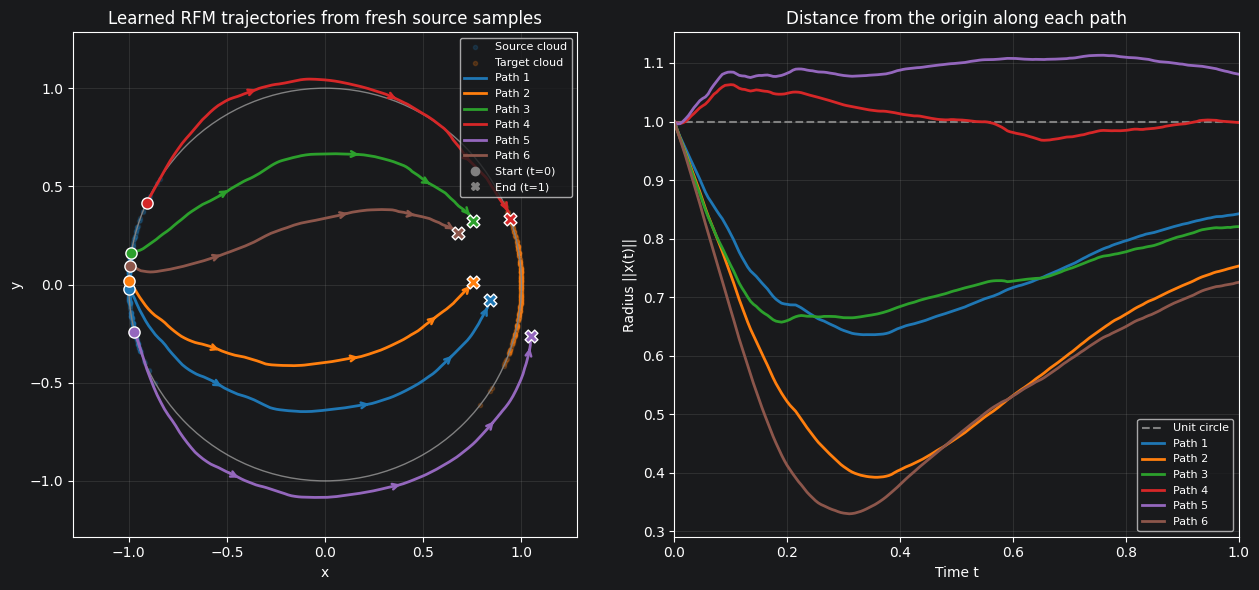

6/6 paths leave the circle at a saved time.


In [27]:
from matplotlib.lines import Line2D

rfm_new_path_radii = np.linalg.norm(rfm_new_trajectories, axis=2)
rfm_new_path_in_circle = np.abs(rfm_new_path_radii - radius) <= 1e-4
rfm_new_path_summary = pd.DataFrame(
    {
        "start_x": rfm_new_start_points[:, 0],
        "start_y": rfm_new_start_points[:, 1],
        "end_x": rfm_new_trajectories[:, -1, 0],
        "end_y": rfm_new_trajectories[:, -1, 1],
        "min_sampled_radius": rfm_new_path_radii.min(axis=1),
        "max_sampled_radius": rfm_new_path_radii.max(axis=1),
        "endpoint_in_circle": rfm_new_path_in_circle[:, -1],
        "all_saved_points_in_circle": rfm_new_path_in_circle.all(axis=1),
        "adaptive_solver_steps": np.asarray(rfm_new_solver_steps),
    },
    index=[f"Path {i + 1}" for i in range(rfm_n_new_points)],
)
display(rfm_new_path_summary)

fig, (path_ax, radius_ax) = plt.subplots(1, 2, figsize=(13, 6))
path_ax.scatter(rfm_source[:, 0], rfm_source[:, 1], s=9, alpha=0.2,
                color="tab:blue", label="Source cloud")
path_ax.scatter(rfm_target[:, 0], rfm_target[:, 1], s=9, alpha=0.2,
                color="tab:orange", label="Target cloud")
path_ax.add_patch(plt.Circle((0, 0), radius, fill=False, edgecolor="gray"))
radius_ax.axhline(radius, color="gray", linestyle="--", label="Unit circle")

rfm_path_colors = plt.get_cmap("tab10")
for path_idx, path in enumerate(rfm_new_trajectories):
    color = rfm_path_colors(path_idx % 10)
    label = f"Path {path_idx + 1}"
    path_ax.plot(path[:, 0], path[:, 1], color=color, linewidth=2, label=label)
    path_ax.scatter(*path[0], s=65, color=color, edgecolor="white", zorder=5)
    path_ax.scatter(*path[-1], marker="X", s=85, color=color, edgecolor="white", zorder=6)
    # Arrows follow the curve at evenly spaced saved times.
    for time_idx in np.linspace(25, len(path) - 15, 4, dtype=int):
        path_ax.annotate(
            "", xy=path[time_idx + 4], xytext=path[time_idx],
            arrowprops={"arrowstyle": "->", "color": color, "lw": 1.8},
        )
    radius_ax.plot(rfm_trajectory_times, rfm_new_path_radii[path_idx],
                   color=color, linewidth=2, label=label)

rfm_path_extent = max(plot_limit, float(np.max(np.abs(rfm_new_trajectories))) + 0.2)
path_ax.set(
    aspect="equal", xlabel="x", ylabel="y",
    xlim=(-rfm_path_extent, rfm_path_extent),
    ylim=(-rfm_path_extent, rfm_path_extent),
    title="Learned RFM trajectories from fresh source samples",
)
handles, labels = path_ax.get_legend_handles_labels()
handles.extend([
    Line2D([], [], linestyle="none", marker="o", color="gray", label="Start (t=0)"),
    Line2D([], [], linestyle="none", marker="X", color="gray", label="End (t=1)"),
])
path_ax.legend(handles=handles, loc="upper right", fontsize=8)
radius_ax.set(xlabel="Time t", ylabel="Radius ||x(t)||", xlim=(0, 1),
              title="Distance from the origin along each path")
radius_ax.legend(fontsize=8, loc="best")
for ax in (path_ax, radius_ax):
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print(f"{np.count_nonzero(~rfm_new_path_in_circle.all(axis=1))}/{rfm_n_new_points} paths leave the circle at a saved time.")